<a href="https://colab.research.google.com/github/Soraia-Costa/Analise-de-dados_Programaria/blob/main/Exemplo__consultorio_medico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [105]:
import pandas as pd


In [114]:
import  matplotlib.pyplot as plt

In [106]:
dados = pd.read_excel("/content/drive/MyDrive/Nova pasta/Aula_aovivo_2/Cópia de Base_Clinica_Aula_13_10.xlsx")


In [96]:
#Quantas linhas e colunas ?
dados.shape

(420, 10)

In [97]:
#Qauis sao as colunas?
dados.columns

Index(['id_atendimento', 'data', 'unidade', 'especialidade', 'idade',
       'canal_agendamento', 'compareceu', 'tempo_espera_min', 'satisfacao_1a5',
       'duracao_consulta_min'],
      dtype='object')

In [98]:
#Tipos de dados e quantidade de valores não nulos
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id_atendimento        420 non-null    int64         
 1   data                  420 non-null    datetime64[ns]
 2   unidade               420 non-null    object        
 3   especialidade         420 non-null    object        
 4   idade                 406 non-null    float64       
 5   canal_agendamento     412 non-null    object        
 6   compareceu            420 non-null    object        
 7   tempo_espera_min      363 non-null    float64       
 8   satisfacao_1a5        356 non-null    float64       
 9   duracao_consulta_min  354 non-null    float64       
dtypes: datetime64[ns](1), float64(4), int64(1), object(4)
memory usage: 32.9+ KB


Onde estão os valores faltantes?


In [107]:
#somando os valores nulos
dados.isna().sum()

,0
id_atendimento,0
data,0
unidade,0
especialidade,0
idade,14
canal_agendamento,8
compareceu,0
tempo_espera_min,57
satisfacao_1a5,64
duracao_consulta_min,66


In [ ]:
#Compare quem faltou à consulta com tempo de espera e satisfação
#Dica: Filtre comparece == 'Não'

dados[dados["compareceu"]=="Não"]

,id_atendimento,data,unidade,especialidade,idade,canal_agendamento,compareceu,tempo_espera_min,satisfacao_1a5,duracao_consulta_min
3,50004,2026-09-23,Norte,Ginecologia,29.0,Telefone,Não,NaN,NaN,NaN
4,50005,2026-09-05,Sul,Ortopedia,62.0,Telefone,Não,NaN,NaN,NaN
17,50018,2026-09-26,Norte,Pediatria,0.0,NaN,Não,NaN,NaN,NaN
26,50027,2026-09-06,Sul,Ginecologia,58.0,Recepção,Não,NaN,NaN,NaN
37,50038,2026-09-13,Norte,Clínica Geral,22.0,App,Não,NaN,NaN,NaN
39,50040,2026-09-29,Norte,Ginecologia,19.0,Telefone,Não,NaN,NaN,NaN
51,50052,2026-09-26,Centro,Pediatria,NaN,Telefone,Não,NaN,NaN,NaN
61,50062,2026-09-26,Sul,Ginecologia,25.0,App,Não,NaN,NaN,NaN
81,50082,2026-09-18,Norte,Clínica Geral,43.0,Recepção,Não,NaN,NaN,NaN
84,50085,2026-09-18,Centro,Clínica Geral,67.0,App,Não,NaN,NaN,NaN


In [ ]:
#Quantos canais de agendamento estão vazios?
dados["canal_agendamento"].isna().sum()

np.int64(8)

In [ ]:
#Crie uma copia de base para trabalhar
dados_limpos=dados.copy()

In [ ]:
#Preencha canal_agendamento vazio com 'Não informado'
dados["canal_agendamento"].value_counts()

,count
canal_agendamento,
App,201
Telefone,126
Recepção,85


In [ ]:
dados_limpos["canal_agendamento"]= dados_limpos["canal_agendamento"].fillna("Não informado")

In [ ]:
dados_limpos["canal_agendamento"].value_counts()

,count
canal_agendamento,
App,201
Telefone,126
Recepção,85
Não informado,8


In [ ]:
#nulo numerico:duração consulta
#Media, mediana, minimo, maximo de duração
dados_limpos["duracao_consulta_min"].describe()

,duracao_consulta_min
count,354.000000
mean,26.686441
std,6.634999
min,8.000000
25%,22.000000
50%,27.000000
75%,31.000000
max,48.000000


In [108]:
#Calcule a mediana - valor do meio
mediana_duracao=dados_limpos["duracao_consulta_min"].median()
mediana_duracao

27.0

In [109]:
#Tempo maximo da consulta
maximo_duracao=dados_limpos["duracao_consulta_min"].max()
maximo_duracao


48.0

In [110]:
#Tempo minimo da consulta
minimo_duracao=dados_limpos["duracao_consulta_min"].min()
minimo_duracao

8.0

In [111]:
#moda o valor que mais aparece
moda_duracao=dados_limpos["duracao_consulta_min"].mode()
moda_duracao

,duracao_consulta_min
0,27.0


In [ ]:
#Preencha SOMENTE os registros em que houve consulta, mas a duração ficou vazia
#Dica: combine compareceu =="Sim com isna()"
mascara_duracao = ( (dados_limpos["compareceu"] == "Sim") &
                    (dados_limpos["duracao_consulta_min"].isna()) )
mascara_duracao

,0
0,False
1,False
2,False
3,False
4,False
...,...
415,False
416,False
417,False
418,False


In [112]:

#Um jeito diferente de fazer fillna
dados_limpos.loc[mascara_duracao, "duracao_consulta_min"] = mediana_duracao
dados_limpos

,id_atendimento,data,unidade,especialidade,idade,canal_agendamento,compareceu,tempo_espera_min,satisfacao_1a5,duracao_consulta_min
0,50001,2026-09-18,Centro,Pediatria,13.0,App,Sim,165.0,1.0,25.0
1,50002,2026-09-18,Centro,Ginecologia,39.0,App,Sim,190.0,1.0,21.0
2,50003,2026-09-18,Centro,Clínica Geral,75.0,Telefone,Sim,235.0,1.0,29.0
3,50004,2026-09-23,Norte,Ginecologia,29.0,Telefone,Não,NaN,NaN,NaN
4,50005,2026-09-05,Sul,Ortopedia,62.0,Telefone,Não,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
415,50416,2026-09-27,Norte,Pediatria,10.0,Telefone,Sim,15.0,4.0,33.0
416,50417,2026-09-08,Centro,Ortopedia,45.0,Telefone,Sim,38.0,3.0,14.0
417,50418,2026-09-27,Norte,Clínica Geral,67.0,App,Sim,31.0,3.0,31.0
418,50419,2026-09-24,Centro,Ortopedia,66.0,Telefone,Sim,36.0,4.0,36.0


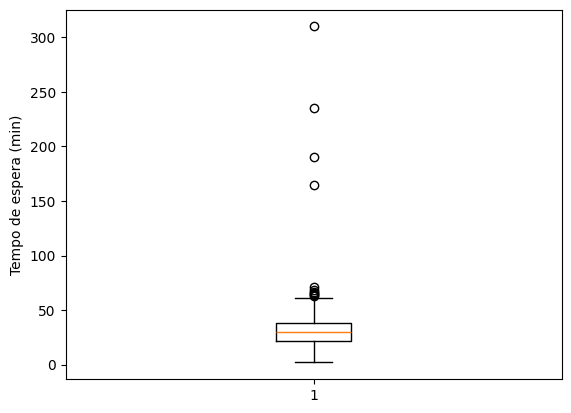

In [116]:
#Faça um boxplot
plt.boxplot(dados_limpos["tempo_espera_min"].dropna())
plt.ylabel("Tempo de espera (min)")
plt.show()

In [122]:
from numpy import quantile
#Calculando quartis
q1=dados_limpos["tempo_espera_min"].quantile(0.25)
q3 =dados_limpos["tempo_espera_min"].quantile(0.75)
iqr = q3 - q1

limite_inferior=q1-(1.5*iqr)
limite_superior=q3+(1.5*iqr)

q1,q3,iqr,limite_inferior, limite_superior

(np.float64(22.0),
 np.float64(38.0),
 np.float64(16.0),
 np.float64(-2.0),
 np.float64(62.0))

In [127]:
outliers_espera = dados_limpos[
    dados_limpos["tempo_espera_min"]>limite_superior
    ]

In [130]:
outliers_espera [
    ["id_atendimento","data","unidade","tempo_espera_min","especialidade"]
].sort_values(by="tempo_espera_min", ascending=False)


,id_atendimento,data,unidade,tempo_espera_min,especialidade
5,50006,2026-09-18,Centro,310.0,Clínica Geral
2,50003,2026-09-18,Centro,235.0,Clínica Geral
1,50002,2026-09-18,Centro,190.0,Ginecologia
0,50001,2026-09-18,Centro,165.0,Pediatria
370,50371,2026-09-29,Centro,71.0,Ginecologia
28,50029,2026-09-22,Centro,68.0,Pediatria
54,50055,2026-09-22,Centro,67.0,Clínica Geral
73,50074,2026-09-30,Centro,66.0,Ginecologia
334,50335,2026-09-12,Sul,65.0,Ginecologia
126,50127,2026-09-27,Centro,64.0,Clínica Geral


Incosistencia de idade


In [135]:
#Procure idades acima de 110
dados_limpos[dados_limpos["idade"] > 110][
  ["id_atendimento","especialidade","idade"]
]

,id_atendimento,especialidade,idade
118,50119,Pediatria,214.0


In [136]:
#Compare media e mediana do tempo de espera
media_espera = dados_limpos [ "tempo_espera_min"].mean()
mediana_espera = dados_limpos["tempo_espera_min"].median()

media_espera, mediana_espera

(np.float64(32.5564738292011), 30.0)